# Math 32 — Lecture 29: From Confidence Intervals to Hypothesis Tests

Companion notebook for Lecture 29. Every figure and number in the slides is made here.

**How this notebook is organized.** Every code cell is **self-contained**, so you can change a number
(the number of heads, $n$, the confidence level, the seed, ...) and re-run just that cell.
Figures are saved in a `figures/` folder next to the notebook.

**The decision rule.** To test a claim like "$p = 0.5$" at level $\alpha$, build the $100(1-\alpha)\%$ confidence interval.
If the claimed value is **outside**, reject the claim; if it is **inside**, fail to reject it.

## 1. Is this coin fair? What would a fair coin do?

Your friend's coin gave **61 heads in 100 flips**. We simulate 200,000 people flipping a *fair* coin 100 times
and ask how often they get a result at least as far from 50 as 61 is.

**Try it:** change `observed` to `55` or `70`. How surprising is each result for a fair coin?

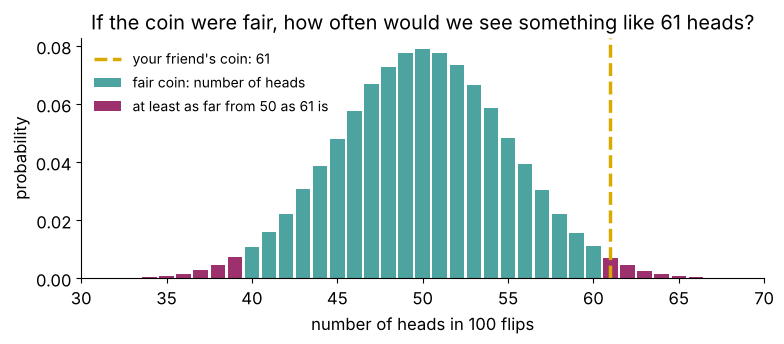

P(at least 61 heads)            = 0.01753
P(at least 11 away from 50)      = 0.035615


In [1]:
# Is this coin fair?  How surprising are 61 heads in 100 flips of a FAIR coin?
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

rng = np.random.default_rng(29)
reps, n, observed = 200_000, 100, 61
heads = rng.binomial(n, 0.5, size=reps)          # 200,000 people each flip a FAIR coin 100 times
vals, counts = np.unique(heads, return_counts=True)
far = np.abs(vals - 50) >= abs(observed - 50)    # at least as far from 50 as 61 is

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(vals[~far], counts[~far] / reps, width=0.85, color=TEAL, alpha=0.7, label="fair coin: number of heads")
ax.bar(vals[far], counts[far] / reps, width=0.85, color=MAGENTA, label=r"at least as far from 50 as 61 is")
ax.axvline(observed, color=GOLD, lw=2.5, ls="--", label="your friend's coin: 61")
ax.set(xlim=(30, 70), xlabel="number of heads in 100 flips", ylabel="probability",
       title="If the coin were fair, how often would we see something like 61 heads?")
ax.legend(frameon=False, loc="upper left", fontsize=10)
fig.tight_layout()
fig.savefig(OUTDIR / "fair_coin_heads.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()
print("P(at least 61 heads)            =", np.mean(heads >= observed))
print("P(at least 11 away from 50)      =", np.mean(np.abs(heads - 50) >= 11))

## 2. Confidence intervals for the coin

$$\hat p \ \pm\ z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}{n}}$$

At 95%, the claimed value $0.5$ is **outside** the interval, so we reject "the coin is fair."
At 99%, $0.5$ is **inside**, so we fail to reject. The decision depends on $\alpha$!

**Try it:** what if the coin gave 610 heads in 1000 flips (the same 61%)? Change `n` and `x`. Is 0.5 still inside?

In [2]:
# Confidence intervals for the coin at 95% and 99%
from math import sqrt
n, x = 100, 61
phat = x / n
se = sqrt(phat * (1 - phat) / n)
print(f"phat = {phat}, standard error = {se:.4f}")
for level, z in [(0.95, 1.96), (0.99, 2.575)]:
    m = z * se
    lo, hi = phat - m, phat + m
    print(f"{int(level*100)}% CI: ({lo:.4f}, {hi:.4f})   contains 0.5? {lo < 0.5 < hi}")

phat = 0.61, standard error = 0.0488
95% CI: (0.5144, 0.7056)   contains 0.5? False
99% CI: (0.4844, 0.7356)   contains 0.5? True


## 3. Even a fair coin gets "rejected" sometimes

Fifty people each flip a **fair** coin 100 times and build a 95% confidence interval. About 5% of the intervals
miss $p = 0.5$, so those people would wrongly decide "not fair." That's the price of testing at level $\alpha = 0.05$.

**Try it:** change `1.96` to `2.575` (99%). How many people wrongly reject now?

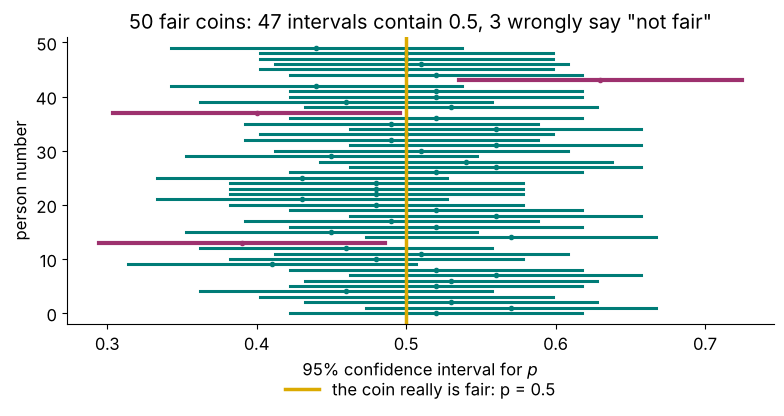

fraction of 200,000 fair coins wrongly called 'not fair': 0.056885


In [3]:
# Even a FAIR coin gets "rejected" sometimes: 50 people, each flips a fair coin 100 times
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

rng = np.random.default_rng(2)
people, n, p = 50, 100, 0.5
phat = rng.binomial(n, p, size=people) / n
m = 1.96 * np.sqrt(phat * (1 - phat) / n)
lo, hi = phat - m, phat + m
contains = (lo < p) & (p < hi)

fig, ax = plt.subplots(figsize=(8, 4.4))
for i in range(people):
    c = TEAL if contains[i] else MAGENTA
    ax.plot([lo[i], hi[i]], [i, i], color=c, lw=2.2 if contains[i] else 3)
    ax.plot(phat[i], i, "o", ms=3, color=c)
ax.axvline(p, color=GOLD, lw=2.5, label="the coin really is fair: p = 0.5")
ax.set(xlabel=r"95% confidence interval for $p$", ylabel="person number", ylim=(-2, people + 1),
       title=f"50 fair coins: {contains.sum()} intervals contain 0.5, {people - contains.sum()} wrongly say \"not fair\"")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14))
fig.tight_layout()
fig.savefig(OUTDIR / "fair_coin_intervals.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

ph = np.random.default_rng(1).binomial(n, p, size=200_000) / n
mm = 1.96 * np.sqrt(ph * (1 - ph) / n)
print("fraction of 200,000 fair coins wrongly called 'not fair':", np.mean(np.abs(ph - p) >= mm))

## 4. Your turn: are the cereal boxes underfilled?

The company claims $\mu = 500$ g. A sample of $n = 30$ boxes has $\bar x = 496$ g and $s = 9$ g.
Since $\sigma$ is unknown, use $t_{29,\,0.025} = 2.045$ (Table B.2).

**Try it:** what if the sample average were $\bar x = 498$ g? Would we still reject the claim?

In [4]:
# Your turn: the cereal boxes (sigma unknown, so use t)
from math import sqrt
n, xbar, s, claim = 30, 496, 9, 500
t29 = 2.045                                  # t_{29, 0.025} from Table B.2
se = s / sqrt(n)
m = t29 * se
print(f"standard error = {se:.4f}, margin = {m:.4f}, 95% CI = ({xbar - m:.2f}, {xbar + m:.2f})")
print("Is the claimed 500 g inside?", xbar - m < claim < xbar + m)

standard error = 1.6432, margin = 3.3603, 95% CI = (492.64, 499.36)
Is the claimed 500 g inside? False
